# Simple and Multiple Linear Regression

Main reference: Joel Grus, *Data Science do Zero: Noções Fundamentais com Python*, 2nd ed., Alta Books, 2020.

Objective: use `sklearn.linear_model.LinearRegression` as a baseline for regression, coefficient interpretation, residual analysis, and the metrics already covered: $R^2$, MAE, MSE and RMSE.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Directories used by the notebook.
FIG_DIR = Path('figures')
DATA_DIR = Path('data')
FIG_DIR.mkdir(exist_ok=True)

# Fixed random generator for the synthetic examples.
SEED = 42
rng = np.random.default_rng(SEED)

# Standardized visual settings for all exported figures.
plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 220,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

def metrics(y_true, y_pred):
    # Computes the metrics already discussed in class.
    mse = mean_squared_error(y_true, y_pred)
    return {
        'R2': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
    }


## Formulation

### Simple linear regression

$$
\hat{y}_i = \beta_0 + \beta_1 x_i
$$

### Multiple linear regression

For sample $i$ with $p$ input variables:

$$
\hat{y}_i
= \beta_0
+ \beta_1 x_{i,1}
+ \beta_2 x_{i,2}
+ \cdots
+ \beta_p x_{i,p}.
$$

In matrix form:

$$
\hat{\mathbf{y}} = \mathbf{X}\boldsymbol{\beta}.
$$

### Least-squares fitting

The parameters are chosen to minimize the sum of squared residuals:

$$
\boldsymbol{\beta}^{\star}
=
\arg\min_{\boldsymbol{\beta}}
\sum_{i=1}^{n}
\left(
y_i - \hat{y}_i
\right)^2.
$$

The residual for sample $i$ is:

$$
e_i = y_i - \hat{y}_i.
$$

## Example: resistance estimation

In a resistor bench test, Ohm’s law imposes a linear relationship between voltage and current:

$$
V_i = R I_i.
$$

To respect the physics of the problem, we fit the regression without an intercept:

$$
\widehat{V}_i = \widehat{R} I_i.
$$

Here the coefficient estimated by the regression is the electrical resistance $\widehat{R}$ itself, in ohms.

In [2]:
# Synthetic test of a 47-ohm resistor.
n = 60
true_resistance = 47.0  # ohms
current = np.linspace(0.01, 0.20, n)  # A
# Uses the same seed defined in the first cell to make this example reproducible.
rng_resistance = np.random.default_rng(SEED)
measurement_noise = rng_resistance.normal(0, 0.18, n)  # V
voltage = true_resistance * current + measurement_noise

# fit_intercept=False forces the line through the origin, as required by V = R I.
X_simple = current.reshape(-1, 1)
simple_model = LinearRegression(fit_intercept=False).fit(X_simple, voltage)
simple_pred = simple_model.predict(X_simple)
simple_residuals = voltage - simple_pred
estimated_resistance = simple_model.coef_[0]

print(f'True resistance: {true_resistance:.2f} ohms')
print(f'Estimated resistance: {estimated_resistance:.2f} ohms')
print(metrics(voltage,simple_pred))

True resistance: 47.00 ohms
Estimated resistance: 47.13 ohms
{'R2': 0.9971837262449934, 'MAE': 0.11451882927873219, 'MSE': 0.01956472269643068, 'RMSE': 0.13987395288770058}


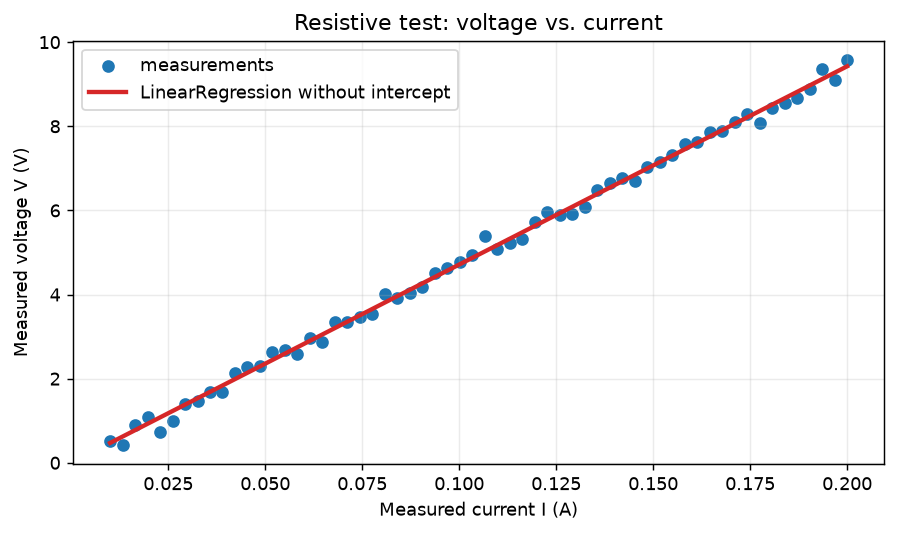

In [3]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.scatter(current, voltage, color='#1f77b4', label='measurements', s=36)
ax.plot(current, simple_pred, color='#d62728', linewidth=2.4, label='LinearRegression without intercept')
ax.set_title('Resistive test: voltage vs. current')
ax.set_xlabel('Measured current I (A)')
ax.set_ylabel('Measured voltage V (V)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_simple_regression.png', bbox_inches='tight')
plt.show()

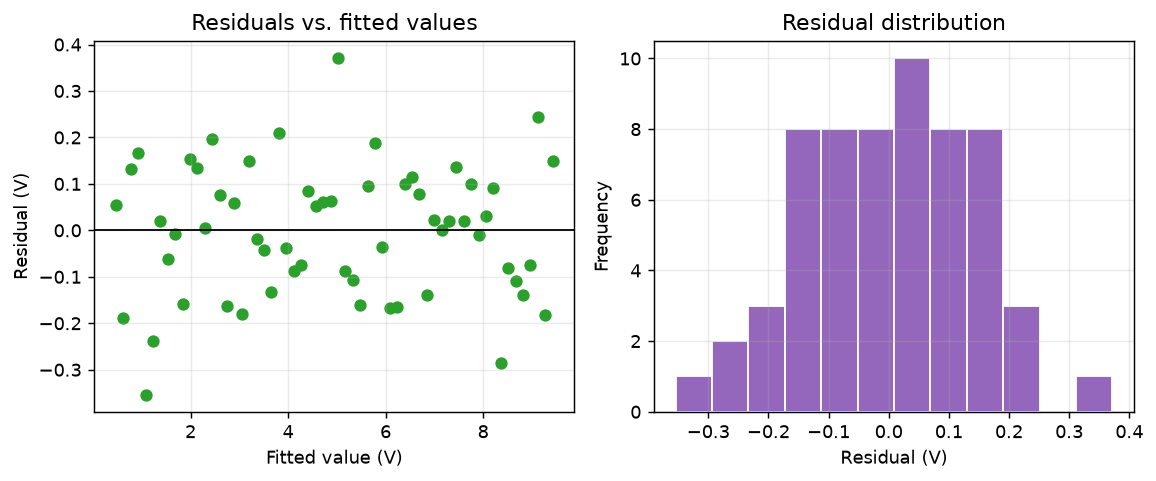

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8))
axes[0].axhline(0, color='black', linewidth=1)
axes[0].scatter(simple_pred, simple_residuals, color='#2ca02c', s=34)
axes[0].set_title('Residuals vs. fitted values')
axes[0].set_xlabel('Fitted value (V)')
axes[0].set_ylabel('Residual (V)')
axes[1].hist(simple_residuals, bins=12, color='#9467bd', edgecolor='white')
axes[1].set_title('Residual distribution')
axes[1].set_xlabel('Residual (V)')
axes[1].set_ylabel('Frequency')
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_simple_residuals.png', bbox_inches='tight')
plt.show()

## Real-world example: combined-cycle power plant

Dataset: **Combined Cycle Power Plant**, UCI Machine Learning Repository.

Source: https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

The dataset contains 9,568 records collected over six years (2006–2011), with the plant operating at full load. Inputs are hourly average ambient variables: ambient temperature (`AT`), exhaust vacuum (`V`), ambient pressure (`AP`), and relative humidity (`RH`). The output is hourly net electrical power (`PE`), in MW.

This is a useful example of linear regression because ambient variables physically affect turbine performance and, within the observed domain, the linear model explains much of the variation in power.

In [5]:
# The file was simplified to a single zipped CSV in data/.
ccpp_path = DATA_DIR / 'combined_cycle_power_plant.csv.zip'

# Direct zip reading with pandas, without manual extraction.
ccpp = pd.read_csv(ccpp_path, compression='zip')

print(ccpp.head())
print(ccpp.describe().round(2))

      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90
            AT        V       AP       RH       PE
count  9568.00  9568.00  9568.00  9568.00  9568.00
mean     19.65    54.31  1013.26    73.31   454.37
std       7.45    12.71     5.94    14.60    17.07
min       1.81    25.36   992.89    25.56   420.26
25%      13.51    41.74  1009.10    63.33   439.75
50%      20.34    52.08  1012.94    74.97   451.55
75%      25.72    66.54  1017.26    84.83   468.43
max      37.11    81.56  1033.30   100.16   495.76


PE = 497.193 + (-2.179) AT
Test - simple AT -> PE model
  R2: 0.8987
  MAE: 4.2745 MW
  MSE: 29.4481 MW^2
  RMSE: 5.4266 MW


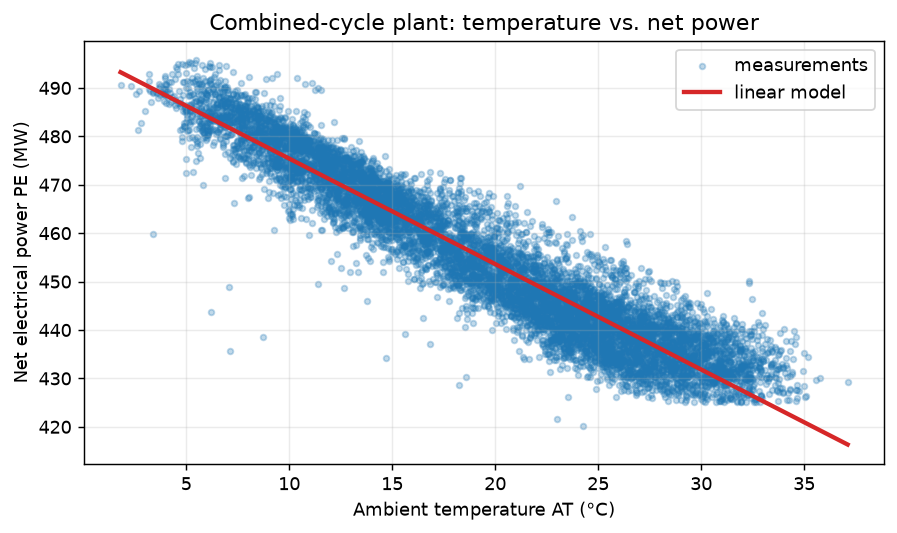

In [6]:
X_at = ccpp[['AT']].to_numpy()
y_pe = ccpp['PE'].to_numpy()
X_train_at, X_test_at, y_train_pe, y_test_pe = train_test_split(X_at, y_pe, test_size=0.25, random_state=42)
at_model = LinearRegression().fit(X_train_at, y_train_pe)
at_pred = at_model.predict(X_test_at)

print(f'PE = {at_model.intercept_:.3f} + ({at_model.coef_[0]:.3f}) AT')
metrics_at = metrics(y_test_pe, at_pred)
print('Test - simple AT -> PE model')
print(f"  R2: {metrics_at['R2']:.4f}")
print(f"  MAE: {metrics_at['MAE']:.4f} MW")
print(f"  MSE: {metrics_at['MSE']:.4f} MW^2")
print(f"  RMSE: {metrics_at['RMSE']:.4f} MW")

order = np.argsort(X_at[:, 0])
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.scatter(ccpp['AT'], ccpp['PE'], s=10, alpha=0.28, color='#1f77b4', label='measurements')
ax.plot(X_at[order, 0], at_model.predict(X_at[order]), color='#d62728', linewidth=2.4, label='linear model')
ax.set_title('Combined-cycle plant: temperature vs. net power')
ax.set_xlabel('Ambient temperature AT (°C)')
ax.set_ylabel('Net electrical power PE (MW)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_ccpp_at_pe.png', bbox_inches='tight')
plt.show()

In [7]:
features_ccpp = ['AT', 'V', 'AP', 'RH']
X = ccpp[features_ccpp].to_numpy()
y = ccpp['PE'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
ccpp_model = LinearRegression().fit(X_train, y_train)
pred_train = ccpp_model.predict(X_train)
pred_test = ccpp_model.predict(X_test)
ccpp_residuals = y_test - pred_test

print(f'Intercept beta0: {ccpp_model.intercept_:.4f} MW')
for name, coef in zip(features_ccpp, ccpp_model.coef_):
    print(f'{name:3s}: {coef: .4f}')
print()
metrics_train_ccpp = metrics(y_train, pred_train)
metrics_test_ccpp = metrics(y_test, pred_test)

print('Train - CCPP')
print(f"  R2: {metrics_train_ccpp['R2']:.4f}")
print(f"  MAE: {metrics_train_ccpp['MAE']:.4f} MW")
print(f"  MSE: {metrics_train_ccpp['MSE']:.4f} MW^2")
print(f"  RMSE: {metrics_train_ccpp['RMSE']:.4f} MW")

print('\nTest - CCPP')
print(f"  R2: {metrics_test_ccpp['R2']:.4f}")
print(f"  MAE: {metrics_test_ccpp['MAE']:.4f} MW")
print(f"  MSE: {metrics_test_ccpp['MSE']:.4f} MW^2")
print(f"  RMSE: {metrics_test_ccpp['RMSE']:.4f} MW")

Intercept beta0: 459.6790 MW
AT : -1.9959
V  : -0.2289
AP :  0.0572
RH : -0.1587

Train - CCPP
  R2: 0.9285
  MAE: 3.6337 MW
  MSE: 20.8369 MW^2
  RMSE: 4.5647 MW

Test - CCPP
  R2: 0.9292
  MAE: 3.5858 MW
  MSE: 20.5819 MW^2
  RMSE: 4.5367 MW


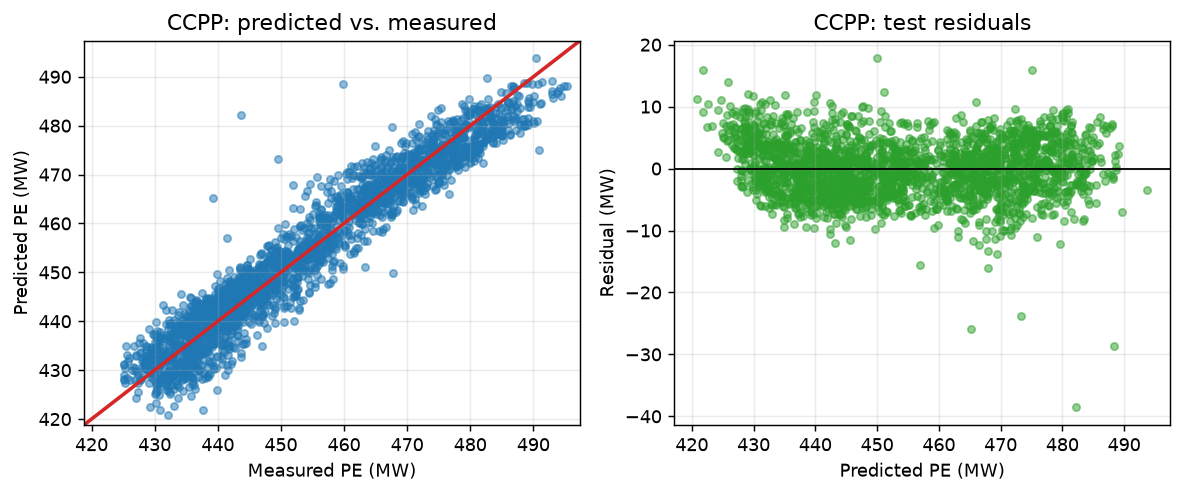

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
axes[0].scatter(y_test, pred_test, s=16, alpha=0.5, color='#1f77b4')
limits = [min(y_test.min(), pred_test.min()) - 2, max(y_test.max(), pred_test.max()) + 2]
axes[0].plot(limits, limits, color='#d62728', linewidth=2)
axes[0].set_xlim(limits)
axes[0].set_ylim(limits)
axes[0].set_title('CCPP: predicted vs. measured')
axes[0].set_xlabel('Measured PE (MW)')
axes[0].set_ylabel('Predicted PE (MW)')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].scatter(pred_test, ccpp_residuals, s=16, alpha=0.5, color='#2ca02c')
axes[1].set_title('CCPP: test residuals')
axes[1].set_xlabel('Predicted PE (MW)')
axes[1].set_ylabel('Residual (MW)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_ccpp_predicted_residuals.png', bbox_inches='tight')
plt.show()

## Real-world example: residential electricity time-series forecasting

Dataset: **Individual Household Electric Power Consumption**, UCI Machine Learning Repository.

Source: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

Here, multiple linear regression is used as a baseline time-series forecasting model. The task is to predict global active power for the next 10-minute interval using recent values from the series, a daily lag, moving averages, and a cyclic encoding of the time of day.

### One-step-ahead forecasting model

We want to predict active power for the next 10-minute interval:

$$
\begin{aligned}
\widehat{P}_{t+1}=\beta_0
&+\beta_1P_t+\beta_2P_{t-1}+\beta_3P_{t-2}
+\beta_4P_{t-6}+\beta_5P_{t-144}\\
&+\beta_6\overline{P}_{1h}+\beta_7\overline{P}_{24h}
+\beta_8\sin\left(\frac{2\pi h_t}{24}\right)
+\beta_9\cos\left(\frac{2\pi h_t}{24}\right).
\end{aligned}
$$

- $P_t$: power measured at the current time.
- $P_{t-1}$, $P_{t-2}$: recent history.
- $P_{t-6}$: approximately one hour earlier.
- $P_{t-144}$: approximately 24 hours earlier.
- $\overline{P}_{1h}$: average power over the previous hour.
- $\overline{P}_{24h}$: average power over the previous 24 hours.
- $\sin(2\pi h_t/24)$, $\cos(2\pi h_t/24)$: encode the hour as a daily cycle.


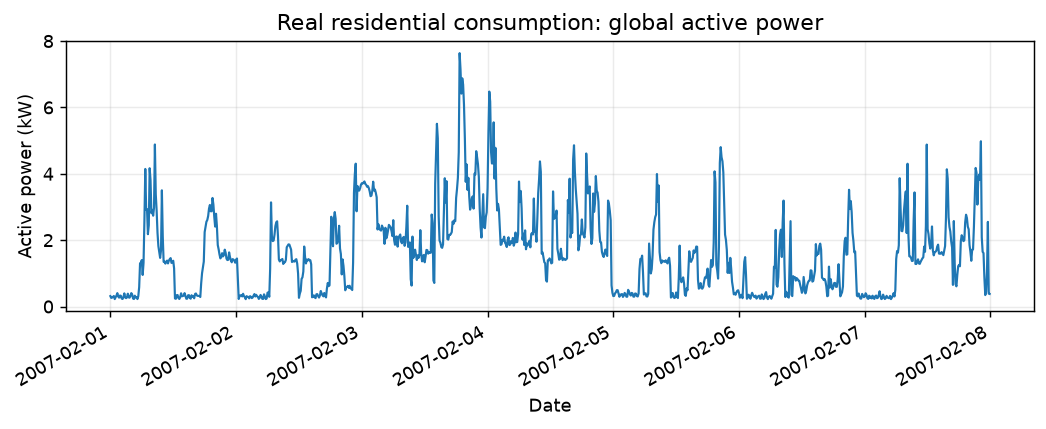

       Global_active_power    Voltage  Global_intensity
count            25690.000  25690.000         25690.000
mean                 1.165    239.209             4.975
std                  1.128      3.515             4.767
min                  0.084    225.701             0.400
25%                  0.299    236.670             1.340
50%                  0.657    239.630             2.900
75%                  1.644    241.780             6.960
max                  8.532    249.992            36.980


In [9]:
# UCI dataset already saved as zip directly in the data/ folder.
household_zip = DATA_DIR / 'household_power_consumption.zip'

numeric_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
]

# The zip contains a single text file; pandas reads it directly with compression='zip'.
household_raw = pd.read_csv(
    household_zip,
    sep=';',
    na_values='?',
    low_memory=False,
    compression='zip',
)

# Creates a time index and converts numeric columns.
household_raw['datetime'] = pd.to_datetime(
    household_raw['Date'] + ' ' + household_raw['Time'],
    dayfirst=True,
    errors='coerce',
)
for col in numeric_cols:
    household_raw[col] = pd.to_numeric(household_raw[col], errors='coerce')

# Resamples to 10 minutes and uses a short window to keep execution light.
household_10min = (
    household_raw
    .dropna(subset=['datetime'] + numeric_cols)
    .set_index('datetime')[numeric_cols]
    .resample('10min')
    .mean()
    .dropna()
    .loc['2007-01-01':'2007-06-30']
    .copy()
)

# Context figure: one real week of residential active power.
fig, ax = plt.subplots(figsize=(8.2, 3.4))
segment = household_10min.loc['2007-02-01':'2007-02-07', 'Global_active_power']
ax.plot(segment.index, segment, color='#1f77b4', linewidth=1.2)
ax.set_title('Real residential consumption: global active power')
ax.set_xlabel('Date')
ax.set_ylabel('Active power (kW)')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_household_series.png', bbox_inches='tight')
plt.show()

print(household_10min[['Global_active_power', 'Voltage', 'Global_intensity']].describe().round(3))

In [10]:
# Builds a supervised table from the time series.
ts = household_10min.copy()
p = ts['Global_active_power']

# Lagged variables: recent past and behavior at the same time on the previous day.
ts['P_t'] = p
ts['P_t_minus_1'] = p.shift(1)
ts['P_t_minus_2'] = p.shift(2)
ts['P_t_minus_6'] = p.shift(6)       # 1 hour before, since resolution is 10 min
ts['P_t_minus_144'] = p.shift(144)   # 24 hours before

# Moving averages to represent local trend.
ts['mean_1h'] = p.rolling(6).mean()
ts['mean_24h'] = p.rolling(144).mean()

# Cyclic encoding of the time of day.
hour_decimal = ts.index.hour + ts.index.minute / 60
ts['hour_sin'] = np.sin(2 * np.pi * hour_decimal / 24)
ts['hour_cos'] = np.cos(2 * np.pi * hour_decimal / 24)

# Target: active power in the next 10-minute interval.
ts['P_t_plus_1'] = p.shift(-1)

features_ts = [
    'P_t',
    'P_t_minus_1',
    'P_t_minus_2',
    'P_t_minus_6',
    'P_t_minus_144',
    'mean_1h',
    'mean_24h',
    'hour_sin',
    'hour_cos',
]
target_ts = 'P_t_plus_1'
data_ts = ts[features_ts + [target_ts]].dropna()

# Temporal split: train at the start of the series, test at the end.
split = int(0.70 * len(data_ts))
train_ts = data_ts.iloc[:split]
test_ts = data_ts.iloc[split:]

ts_model = LinearRegression().fit(train_ts[features_ts], train_ts[target_ts])
ts_pred = ts_model.predict(test_ts[features_ts])
ts_residuals = test_ts[target_ts].to_numpy() - ts_pred

metrics_ts = metrics(test_ts[target_ts], ts_pred)
print('Test - temporal active-power forecasting')
print(f"  R2: {metrics_ts['R2']:.4f}")
print(f"  MAE: {metrics_ts['MAE']:.4f} kW")
print(f"  MSE: {metrics_ts['MSE']:.4f} kW^2")
print(f"  RMSE: {metrics_ts['RMSE']:.4f} kW")

coef_ts = pd.Series(ts_model.coef_, index=features_ts).sort_values(key=np.abs, ascending=False)
print('\nCoefficients sorted by magnitude:')
print(coef_ts.round(4))

Test - temporal active-power forecasting
  R2: 0.6995
  MAE: 0.2699 kW
  MSE: 0.2497 kW^2
  RMSE: 0.4997 kW

Coefficients sorted by magnitude:
P_t              0.8808
P_t_minus_1     -0.0864
P_t_minus_2      0.0637
P_t_minus_6      0.0485
mean_24h         0.0389
P_t_minus_144    0.0322
hour_sin        -0.0298
hour_cos        -0.0186
mean_1h         -0.0157
dtype: float64


### Time-series experiment setup

- Resolution after resampling: 10 min.
- Time window: Jan.–Jun. 2007.
- Split: training and test sets.
- Test metrics: $R^2 = 0.6995$, MAE = 0.2699 kW, RMSE = 0.4997 kW.

The model uses persistence, daily patterns, and moving averages to predict the next value in the series.


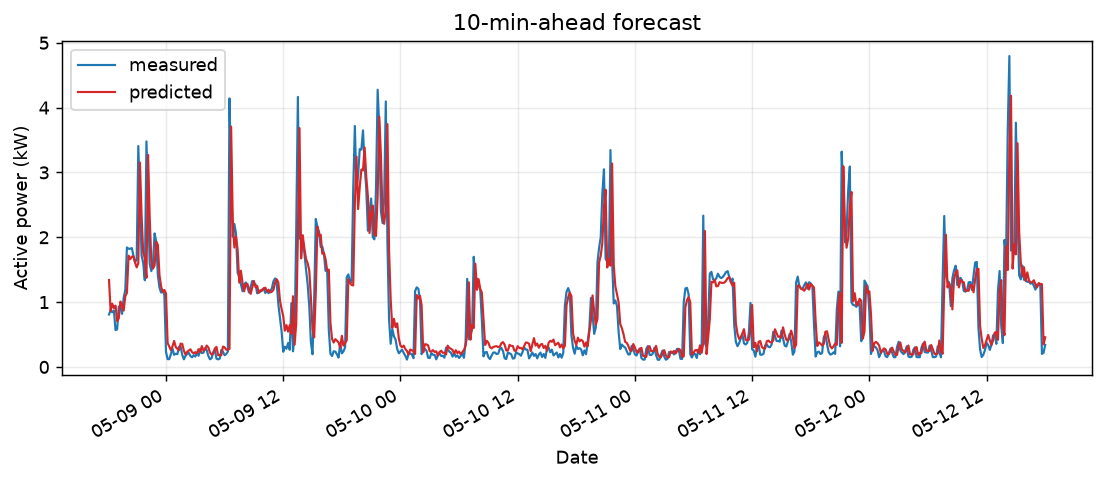

In [11]:
# Common window to compare one-step-ahead forecasting and free-run prediction.
freq_ts = pd.Timedelta('10min')
forecast_window = 6 * 24 * 4  # four days at 10-min resolution
forecast_origins = test_ts.index[:forecast_window]
forecast_time = forecast_origins + freq_ts

# Time evolution of one-step-ahead forecasting.
fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.plot(
    forecast_time,
    test_ts[target_ts].iloc[:forecast_window],
    label='measured',
    color='#1f77b4',
    linewidth=1.2,
)
ax.plot(
    forecast_time,
    ts_pred[:forecast_window],
    label='predicted',
    color='#d62728',
    linewidth=1.2,
)
ax.set_title('10-min-ahead forecast')
ax.set_xlabel('Date')
ax.set_ylabel('Active power (kW)')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_household_temporal_forecast_series.png', bbox_inches='tight')
plt.show()

### One-step-ahead forecasting

In the previous evaluation, we used **one-step-ahead** forecasting:

$$
\widehat{P}_{t+1}=f(P_t, P_{t-1}, P_{t-2}, P_{t-6}, P_{t-144}, \ldots).
$$

- Inputs come from the measured series up to time $t$.
- At each new step, the model receives new real data.
- It is suitable when the system is continuously updated with measurements.

In this setup, a forecast error does not directly affect the model’s next input.


### Free-run prediction

In **free-run prediction**, the model evolves on its own:

$$
\widehat{P}_{t+2}=f(\widehat{P}_{t+1}, P_t, P_{t-1}, P_{t-5}, P_{t-143}, \ldots).
$$

- After the first step, previous predictions become new inputs.
- It is useful for simulating multiple future steps without new measurements.
- Small errors may accumulate over time.

Performance is usually worse than in one-step-ahead forecasting. This is a more demanding test of model quality.


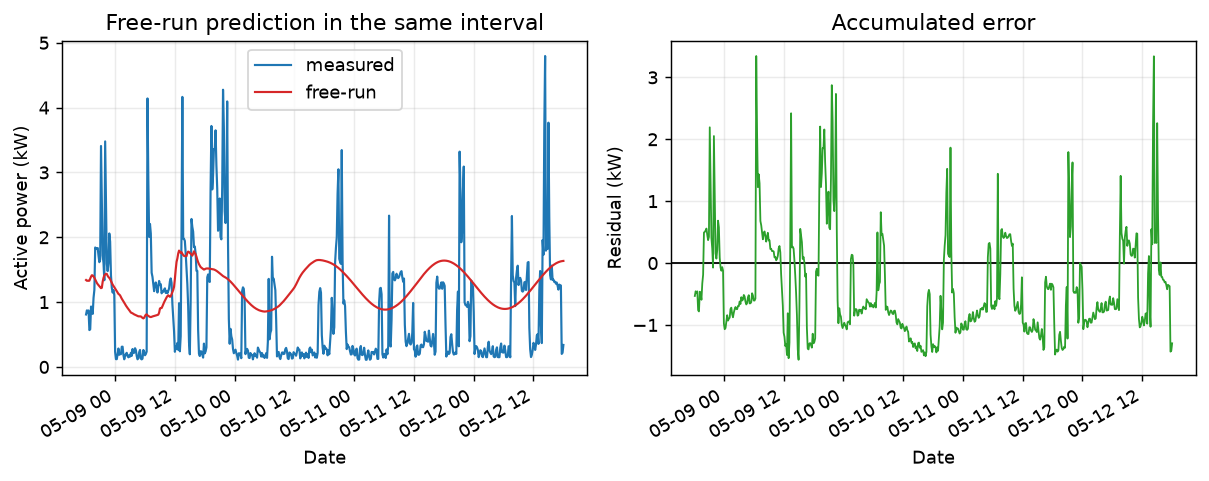

In [12]:
# Free-run prediction: after the first step, the model uses its own predictions.
recursive_series = household_10min['Global_active_power'].copy()
free_pred = []

for origin in forecast_origins:
    hour_decimal = origin.hour + origin.minute / 60

    # Features computed from the recursive series, not from the future real series.
    x_free = pd.DataFrame([{
        'P_t': recursive_series.loc[origin],
        'P_t_minus_1': recursive_series.loc[origin - freq_ts],
        'P_t_minus_2': recursive_series.loc[origin - 2 * freq_ts],
        'P_t_minus_6': recursive_series.loc[origin - 6 * freq_ts],
        'P_t_minus_144': recursive_series.loc[origin - 144 * freq_ts],
        'mean_1h': recursive_series.loc[origin - 5 * freq_ts:origin].mean(),
        'mean_24h': recursive_series.loc[origin - 143 * freq_ts:origin].mean(),
        'hour_sin': np.sin(2 * np.pi * hour_decimal / 24),
        'hour_cos': np.cos(2 * np.pi * hour_decimal / 24),
    }], columns=features_ts)

    next_time = origin + freq_ts
    next_power = float(ts_model.predict(x_free)[0])

    # Feeds the forecast back so following steps do not use future measurements.
    recursive_series.loc[next_time] = next_power
    free_pred.append(next_power)

free_pred = np.array(free_pred)
actual_free = household_10min.loc[forecast_time, 'Global_active_power'].to_numpy()
free_residuals = actual_free - free_pred

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))

# Same timeframe as one-step-ahead forecasting.
axes[0].plot(forecast_time, actual_free, label='measured', color='#1f77b4', linewidth=1.2)
axes[0].plot(forecast_time, free_pred, label='free-run', color='#d62728', linewidth=1.2)
axes[0].set_title('Free-run prediction in the same interval')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Active power (kW)')
axes[0].legend()

# Error over time: error accumulation is visible here.
axes[1].axhline(0, color='black', linewidth=1)
axes[1].plot(forecast_time, free_residuals, color='#2ca02c', linewidth=1.0)
axes[1].set_title('Accumulated error')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Residual (kW)')

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / 'aula10_household_free_run.png', bbox_inches='tight')
plt.show()

### Interpreting free-run prediction

Over the same interval as one-step-ahead forecasting, free-run prediction accumulates error because previous predictions become new model inputs.


## Discussion points

- In the CCPP example, multiple linear regression is a static estimate of net power from ambient conditions; it is not a time-series forecast.
- The CCPP model applies within the observed domain; extrapolation beyond the measured ranges is not guaranteed.
- In the residential time series, one-step-ahead forecasts use real measurements up to the current time.
- In free-run prediction, previous predictions become new inputs and errors may accumulate.